# 05. Final evaluation on 2023

The model and the evaluation rules were frozen before this notebook was run: the 13 features of `features.py`, ordinary least squares, and thresholds set on 2022. The year 2023 is used once. No feature, hyperparameter or decision rule is changed after seeing the results below.

**Question: how accurate is the frozen model on a year it has never seen, and with what uncertainty?**


## 1. Frozen setup


In [1]:
%matplotlib inline
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from features import build_features

project_dir = Path.cwd().parent if Path.cwd().name == "analysis" else Path.cwd()
visits = pd.read_parquet(project_dir / "data/processed/df_cleaned.parquet")["visits"].sort_index()

X, y = build_features(visits)
final_test_start = pd.Timestamp("2023-01-01")
train = X.index < final_test_start
test = ~train

assert test.sum() == 365
assert X.index[test][0] == final_test_start
assert X.index[test][-1] == pd.Timestamp("2023-12-31")

print(f"Train: {train.sum()} days, {X.index[train][0].date()} to {X.index[train][-1].date()}")
print(f"Test:  {test.sum()} days, {X.index[test][0].date()} to {X.index[test][-1].date()}")
print(f"Mean visits: train {y[train].mean():.0f}, test {y[test].mean():.0f}")

Train: 2184 days, 2017-01-08 to 2022-12-31
Test:  365 days, 2023-01-01 to 2023-12-31
Mean visits: train 1673, test 1574


## 2. Point accuracy


In [2]:
model = LinearRegression().fit(X[train], y[train])
predictions = model.predict(X[test])
actual = y[test]

def scores(name, y_true, y_hat):
    return {
        "Model": name,
        "MAE": mean_absolute_error(y_true, y_hat),
        "RMSE": mean_squared_error(y_true, y_hat) ** 0.5,
        "R²": r2_score(y_true, y_hat),
    }

table = pd.DataFrame([
    scores("OLS, 13 features", actual, predictions),
    scores("Previous week", actual, X.loc[test, "visits_lag7"]),
    scores("Previous day", actual, X.loc[test, "visits_lag1"]),
]).round(2)

display(table)
print(f"MAE as a share of the daily mean: {mean_absolute_error(actual, predictions) / actual.mean():.1%}")

,Model,MAE,RMSE,R²
0,"OLS, 13 features",60.68,81.21,0.68
1,Previous week,86.81,110.25,0.40
2,Previous day,105.58,138.69,0.06


MAE as a share of the daily mean: 3.9%


On 2023 the model reaches **MAE 60.68 visits per day**, RMSE 81.21 and R² 0.677. That is 3.9% of the daily mean, against 3.2% in 2022.

The degradation relative to 2022 (52.96) is consistent with the level shift: the 2023 mean is 1 575 visits per day against 1 630 in 2022, a drop of 3.4%. A model trained on a period whose level no longer holds pays a price, and this is the honest figure — the 2022 number was the development period used to choose the features.

The two naive forecasts are far behind: copying the same weekday one week earlier gives MAE 86.81, and copying the previous day gives 105.58. The model therefore removes 26 visits of error against the weekly persistence, and 45 against the daily one.


## 3. Prediction intervals

The intervals are built by split conformal prediction. The point model is trained on 2017–2022 and its residuals are not usable for calibration because they are in-sample. We therefore fit the same model on 2017–2021, measure its absolute errors on the 2022 hold-out, and take the appropriate empirical quantile:

$$q_\alpha = \text{the } \lceil (n+1)(1-\alpha) \rceil \text{-th smallest absolute residual}$$

The interval is then `prediction ± q_α`. This gives a finite-sample guarantee if the calibration year and the test year are exchangeable — an assumption we check below.


In [3]:
calibration_start = pd.Timestamp("2022-01-01")
calibration = (X.index >= calibration_start) & train
reference = LinearRegression().fit(X[X.index < calibration_start], y[X.index < calibration_start])
residuals = np.abs(y[calibration] - reference.predict(X[calibration])).to_numpy()

def conformal_quantile(residuals, alpha):
    n = len(residuals)
    k = int(np.ceil((n + 1) * (1 - alpha)))
    return np.sort(residuals)[min(k, n) - 1]

intervals = {}
rows = []
for alpha in (0.2, 0.1):
    q = conformal_quantile(residuals, alpha)
    lower, upper = predictions - q, predictions + q
    intervals[alpha] = (lower, upper, q)
    rows.append({
        "Nominal coverage": f"{1 - alpha:.0%}",
        "Half-width (visits)": q,
        "Width (visits)": 2 * q,
        "Coverage on 2023": np.mean((actual >= lower) & (actual <= upper)),
    })

coverage_table = pd.DataFrame(rows).round(3)
display(coverage_table)

,Nominal coverage,Half-width (visits),Width (visits),Coverage on 2023
0,80%,85.845,171.689,0.745
1,90%,112.108,224.216,0.866


The 90% interval is **±112 visits** (224 wide) and covers **86.6%** of 2023 days. The 80% interval is ±86 visits and covers **74.5%**.

The shortfall is not a coding error. Conformal validity assumes the calibration year and the test year are exchangeable; 2023 is not a copy of 2022. Its level is lower and its weekly profile differs, so the intervals are slightly too narrow. By quarter, coverage at 90% is 82.2%, 83.5%, 92.4% and 88.0% — the first half of the year, where the level moved most, is where the interval fails.

A model used operationally in 2024 would need to recalibrate on 2023 residuals, not reuse the 2022 quantiles.


## 4. The year, day by day


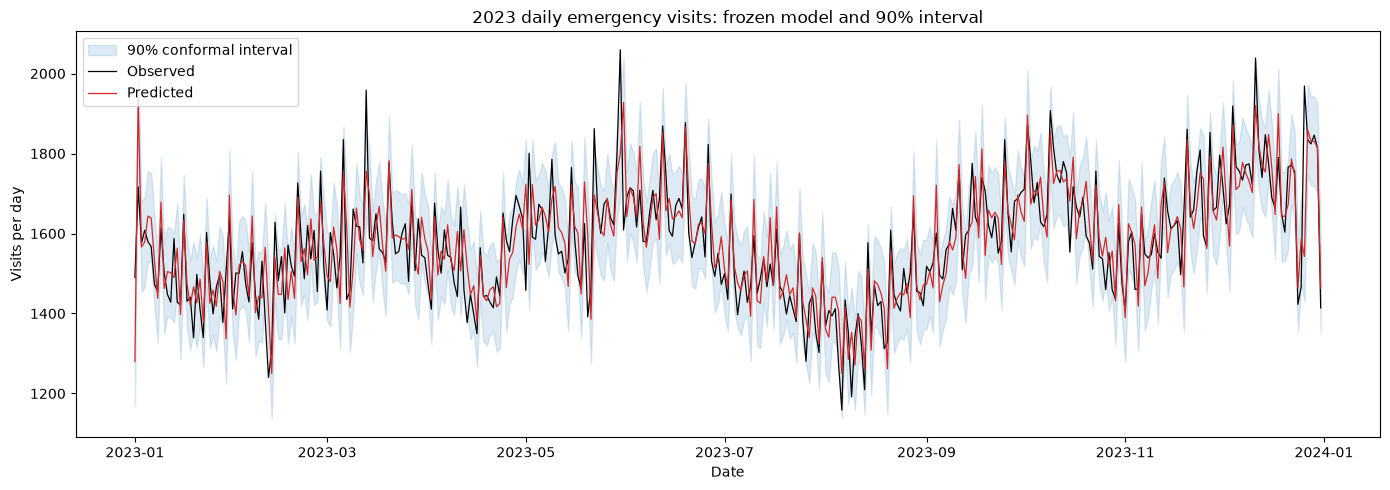

In [4]:
lower90, upper90, _ = intervals[0.1]

fig, ax = plt.subplots(figsize=(14, 5))
ax.fill_between(actual.index, lower90, upper90, color="tab:blue", alpha=0.15, label="90% conformal interval")
ax.plot(actual.index, actual.to_numpy(), color="black", linewidth=0.9, label="Observed")
ax.plot(actual.index, predictions, color="tab:red", linewidth=0.9, label="Predicted")
ax.set_title("2023 daily emergency visits: frozen model and 90% interval")
ax.set_ylabel("Visits per day")
ax.set_xlabel("Date")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

## 5. Where the error comes from


,MAE,Coverage 90%
Month,,
1,69.14,0.84
2,76.81,0.82
3,69.76,0.81
4,57.61,0.83
5,92.97,0.71
6,43.94,0.97
7,40.96,0.97
8,52.67,0.90
9,56.83,0.90


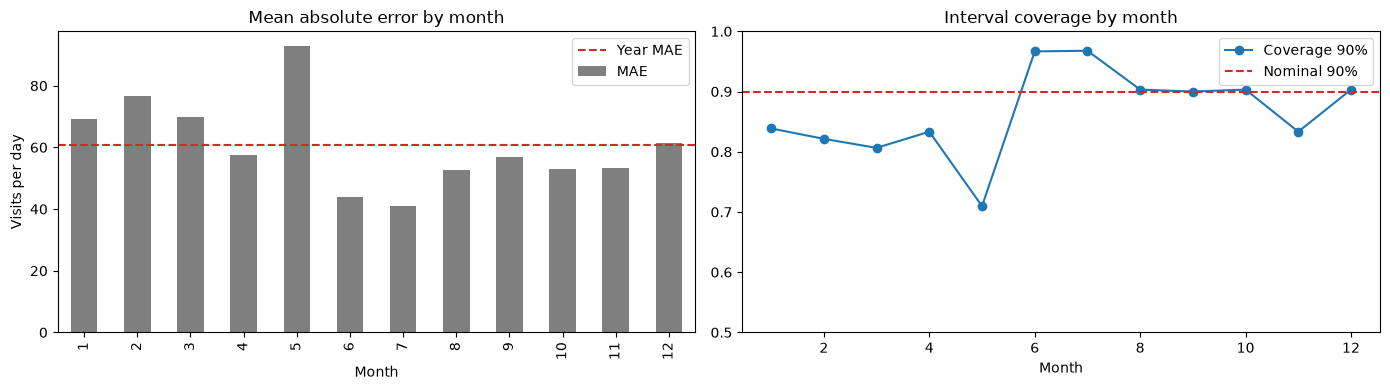

In [5]:
frame = pd.DataFrame(
    {"actual": actual, "predicted": predictions, "lower": lower90, "upper": upper90}
)
monthly = frame.groupby(frame.index.month).apply(
    lambda d: pd.Series({
        "MAE": mean_absolute_error(d["actual"], d["predicted"]),
        "Coverage 90%": ((d["actual"] >= d["lower"]) & (d["actual"] <= d["upper"])).mean(),
    })
)
monthly.index.name = "Month"
display(monthly.round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
monthly["MAE"].plot.bar(ax=axes[0], color="tab:grey")
axes[0].axhline(mean_absolute_error(actual, predictions), color="tab:red", linestyle="--", label="Year MAE")
axes[0].set_title("Mean absolute error by month")
axes[0].set_ylabel("Visits per day")
axes[0].legend()

monthly["Coverage 90%"].plot(ax=axes[1], marker="o", color="tab:blue")
axes[1].axhline(0.9, color="tab:red", linestyle="--", label="Nominal 90%")
axes[1].set_ylim(0.5, 1.0)
axes[1].set_title("Interval coverage by month")
axes[1].legend()

plt.tight_layout()
plt.show()

## 6. Conclusion

| Quantity | 2022 (development) | 2023 (final test) |
|---|---|---|
| MAE | 52.96 | **60.68** |
| RMSE | 67.46 | 81.21 |
| R² | 0.803 | 0.677 |
| 90% interval coverage | — | 86.6% |
| 80% interval coverage | — | 74.5% |

**Answer to the research question.** Daily emergency visits in the Rhône can be forecast one day ahead with an average error of about 61 visits per day, or 3.9% of the daily mean, using only information available the previous day: the two most recent visit counts and the calendar. Daily persistence is far worse (87 and 106 visits), so the model does capture real structure.

**What the result does not support.** The 2022 development figure (52.96) is optimistic by about 8 visits and must not be quoted as the model's performance. The gap comes from a level shift, not from a bug: the 2023 mean is 3.4% below 2022.

**Limits.** The intervals under-cover (86.6% at the 90% level) because exchangeability fails across a drifting level. A production use would recalibrate on the most recent year. The model also has no exogenous input: epidemic indicators, weather, school holidays and the school calendar were all tested in notebooks 03 and 04 and did not survive the validation criteria. The remaining error is dominated by day-to-day shocks that no variable in this dataset explains.
